# ch02_3. 비용함수 최소화

## 개요

- 가중치 $W$에 따라 Cost(코스트, 비용)가 어떻게 변하는지 확인합니다.
- 같은 함수를 센서 데이터에 재사용합니다.

## 1. 데이터와 단순화된 선형식

다음 세 점을 사용합니다.

$$
(1,1),\quad(2,2),\quad(3,3)
$$

데이터의 관계는 $y=x$이므로 가장 적절한 가중치는 $W=1$입니다.

비용곡선을 쉽게 보기 위해 편향 $b$를 잠시 제외합니다.

$$
\hat{y}=Wx
$$

편향이 필요 없다는 뜻이 아니라, **가중치 하나의 이동만 관찰하기 위한 단순화**입니다.

In [1]:
import torch
import matplotlib.pyplot as plt

x_train = torch.tensor([1.0, 2.0, 3.0])
y_train = torch.tensor([1.0, 2.0, 3.0])

print("입력:", x_train)
print("실제값:", y_train)

입력: tensor([1., 2., 3.])
실제값: tensor([1., 2., 3.])


## 2. 가중치에 따른 비용 계산

MSE(엠에스이, 평균제곱오차)는 예측값과 실제값의 차이를 제곱한 뒤 평균합니다.

$$
\mathrm{Cost}(W)
=
\frac{1}{m}
\sum_{i=1}^{m}
(Wx_i-y_i)^2
$$

- $W=1$: 예측값과 실제값이 같으므로 비용은 0
- $W\neq1$: 예측 오차가 생기므로 비용은 0보다 큼

In [2]:
def calculate_cost(weight, x=x_train, y=y_train):
    prediction = weight * x
    return ((prediction - y) ** 2).mean().item()


for weight in [0.0, 1.0, 2.0]:
    cost = calculate_cost(weight)
    print(f"W={weight:.1f} → Cost={cost:.4f}")

W=0.0 → Cost=4.6667
W=1.0 → Cost=0.0000
W=2.0 → Cost=4.6667


## 3. 비용함수 그래프

여러 가중치에서 비용을 계산하면 $W=1$이 최저점인 포물선이 나타납니다.

이 그래프에서:

- 가로축: 가중치 $W$
- 세로축: Cost
- 가장 낮은 점: 가장 좋은 가중치

> **가장 좋은 가중치는 비용곡선의 최저점에 있습니다.**

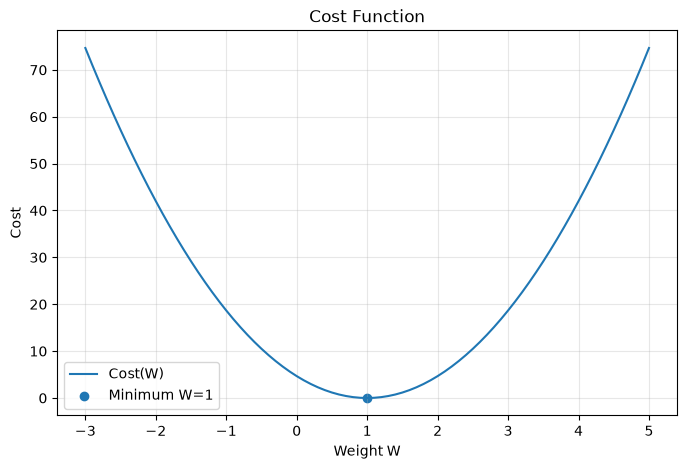

In [3]:
weight_values = torch.linspace(-3.0, 5.0, 161)
cost_values = [
    calculate_cost(weight.item())
    for weight in weight_values
]

plt.figure(figsize=(8, 5))
plt.plot(weight_values.numpy(), cost_values, label="Cost(W)")
plt.scatter([1.0], [0.0], label="Minimum W=1")
plt.xlabel("Weight W")
plt.ylabel("Cost")
plt.title("Cost Function")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 4. 기울기의 의미

Gradient(기울기)는 현재 위치에서 비용이 어느 방향으로 증가하는지 알려줍니다.

- 기울기 $>0$: 오른쪽으로 갈수록 비용 증가 → $W$를 줄여야 함
- 기울기 $<0$: 오른쪽으로 갈수록 비용 감소 → $W$를 늘려야 함
- 기울기 $\approx0$: 비용곡선의 최저점에 가까움

현재 데이터의 기울기는 다음 식으로 계산할 수 있습니다.

$$
\frac{\partial \mathrm{Cost}}{\partial W}
=
\frac{2}{m}
\sum_{i=1}^{m}
(Wx_i-y_i)x_i
$$

In [4]:
# W=5에서 기울기를 계산합니다.
weight = torch.tensor(5.0)

manual_gradient = 2 * (
    (weight * x_train - y_train) * x_train
).mean()

print("현재 W:", weight.item())
print("기울기:", manual_gradient.item())

현재 W: 5.0
기울기: 37.33333206176758


## 5. 직접 계산과 자동미분 비교

PyTorch는 `backward()`를 실행하면 기울기를 자동으로 계산합니다.

직접 계산한 값과 자동미분 결과가 같으면, PyTorch가 같은 미분 계산을 대신 수행한 것입니다.

In [5]:
weight_auto = torch.tensor(
    5.0,
    requires_grad=True,
)

prediction = weight_auto * x_train
cost = ((prediction - y_train) ** 2).mean()

cost.backward()

print("직접 계산:", manual_gradient.item())
print("자동미분:", weight_auto.grad.item())

직접 계산: 37.33333206176758
자동미분: 37.333335876464844


## 6. 경사하강법으로 한 번 이동하기

경사하강법은 기울기의 반대 방향으로 가중치를 이동합니다.

$$
W_{\mathrm{new}}
=
W_{\mathrm{old}}
-
\alpha
\frac{\partial \mathrm{Cost}}{\partial W}
$$

$$여기서 (\alpha)는 Learning Rate(학습률)입니다.$$

- 학습률이 작으면 조금 이동
- 학습률이 크면 많이 이동

In [6]:
learning_rate = 0.1

new_weight = weight - learning_rate * manual_gradient

print("이동 전 W:", weight.item())
print("이동 후 W:", new_weight.item())
print("이동 후 Cost:", calculate_cost(new_weight.item()))

이동 전 W: 5.0
이동 후 W: 1.2666666507720947
이동 후 Cost: 0.3318518102169037


## 7. 재사용 가능한 비용 최소화 함수

 학습 흐름과 같습니다.

$$
\text{Forward}
\rightarrow
\text{Cost}
\rightarrow
\text{Backward}
\rightarrow
\text{Update}
$$

모델 전체가 아니라 가중치 $W$ 하나만 학습합니다.

In [7]:
def minimize_cost(
    x,
    y,
    start_weight,
    learning_rate=0.1,
    epochs=20,
):
    # 학습할 가중치
    W = torch.tensor(
        float(start_weight),
        requires_grad=True,
    )

    optimizer = torch.optim.SGD(
        [W],
        lr=learning_rate,
    )

    weight_history = [W.item()]
    cost_history = [
        ((W * x - y) ** 2).mean().item()
    ]

    for _ in range(epochs):
        # 1. 순전파
        prediction = W * x

        # 2. 비용 계산
        cost = ((prediction - y) ** 2).mean()

        # 3. 기울기 초기화
        optimizer.zero_grad()

        # 4. 역전파
        cost.backward()

        # 5. 가중치 갱신
        optimizer.step()

        # 갱신된 결과 기록
        with torch.no_grad():
            new_cost = ((W * x - y) ** 2).mean()

        weight_history.append(W.item())
        cost_history.append(new_cost.item())

    return W.detach(), weight_history, cost_history

## 8. 가중치가 최저점으로 이동하는 과정

시작 가중치를 $W=5$로 설정합니다.

학습이 진행되면:

- $W$는 1에 가까워짐
- Cost는 0에 가까워짐

In [8]:
final_weight, weight_history, cost_history = minimize_cost(
    x_train,
    y_train,
    start_weight=5.0,
    learning_rate=0.1,
    epochs=20,
)

print("시작 W:", weight_history[0])
print("최종 W:", final_weight.item())
print("시작 Cost:", cost_history[0])
print("최종 Cost:", cost_history[-1])

시작 W: 5.0
최종 W: 1.0
시작 Cost: 74.66666412353516
최종 Cost: 0.0


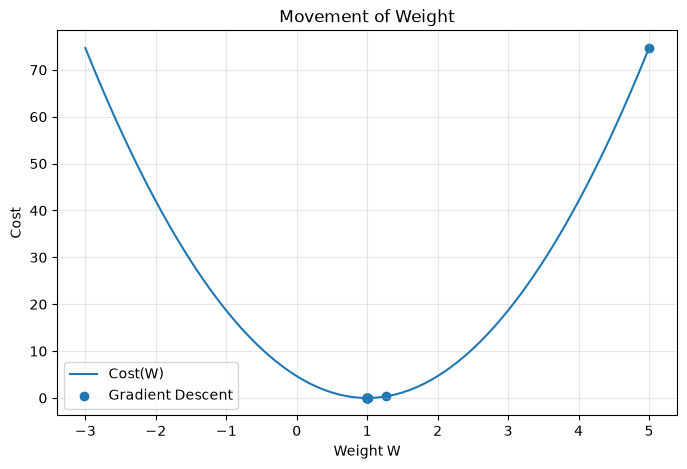

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(weight_values.numpy(), cost_values, label="Cost(W)")
plt.scatter(
    weight_history,
    cost_history,
    label="Gradient Descent",
)
plt.xlabel("Weight W")
plt.ylabel("Cost")
plt.title("Movement of Weight")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 9. 학습률 비교

학습률은 한 번에 이동하는 크기입니다.

| 학습률 | 특징 |
|---:|---|
| 너무 작음 | 안정적이지만 느림 |
| 적절함 | 빠르고 안정적으로 수렴 |
| 너무 큼 | 최저점을 지나치며 발산할 수 있음 |

아래에서는 같은 시작점에서 학습률만 바꾸어 비교합니다.

In [10]:
for rate in [0.01, 0.1, 0.3]:
    result_W, _, result_costs = minimize_cost(
        x_train,
        y_train,
        start_weight=5.0,
        learning_rate=rate,
        epochs=10,
    )

    print(
        f"학습률={rate:.2f} → "
        f"최종 W={result_W.item():.4f}, "
        f"최종 Cost={result_costs[-1]:.4f}"
    )

학습률=0.01 → 최종 W=2.5015, 최종 Cost=10.5216
학습률=0.10 → 최종 W=1.0000, 최종 Cost=0.0000
학습률=0.30 → 최종 W=1429.1888, 최종 Cost=9518709.0000


## 10. 실무 예제: 센서 출력 비율 학습

입력과 출력의 관계가 다음과 같은 센서 데이터를 사용합니다.

$$
y=2x
$$

따라서 목표 가중치는 $W=2$입니다.

앞에서 만든 `minimize_cost()` 함수를 그대로 재사용합니다.

In [11]:
sensor_x = torch.tensor([1.0, 2.0, 3.0])
sensor_y = torch.tensor([2.0, 4.0, 6.0])

sensor_W, _, sensor_costs = minimize_cost(
    sensor_x,
    sensor_y,
    start_weight=-3.0,
    learning_rate=0.1,
    epochs=20,
)

new_input = torch.tensor(4.0)

with torch.no_grad():
    new_output = sensor_W * new_input

print("학습된 W:", sensor_W.item())
print("최종 Cost:", sensor_costs[-1])
print("입력 4의 예측값:", new_output.item())

학습된 W: 2.0
최종 Cost: 0.0
입력 4의 예측값: 8.0


## 12. 핵심 정리

- Cost는 예측값과 실제값의 차이를 나타냅니다.
- 학습률은 한 번에 이동하는 크기를 결정합니다.
- 같은 최소화 함수는 다른 선형 데이터에도 재사용할 수 있습니다.